# Taller de Aprendizaje No Supervisado
## Parte 2: Segmentación de Clientes de Tarjeta de Crédito (variables numéricas)

### Credit Card Dataset

[Credit Card Dataset for Clustering](https://www.kaggle.com/datasets/arjunbhasin2013/ccdata)

Resume el comportamiento de uso de unos **9.000 titulares** de tarjeta durante los últimos 6 meses, con **17 variables numéricas de comportamiento** (saldo, compras, adelantos de efectivo, límite de crédito, pagos...).

> **Diferencia clave con el dataset de setas:** aquí **no hay etiqueta**. El objetivo *es* encontrar segmentos de clientes para definir una estrategia de marketing. Esto es aprendizaje no supervisado «de verdad»: no podemos calcular ARI porque no hay verdad de referencia; nos guiamos por métricas internas y por la **interpretabilidad** de los segmentos.

Además, al ser numérico y con escalas muy distintas, aparecen dos pasos que con las setas no hicieron falta: **imputar nulos** y **escalar**.

In [22]:
%matplotlib inline
# Hace que los gráficos aparezcan dentro del notebook, justo debajo de la celda que los crea.
import warnings
warnings.filterwarnings("ignore")  # oculta avisos para que la salida quede limpia

import pandas as pd      # tablas (DataFrame)
import numpy as np       # arrays y cálculo numérico
import seaborn as sns            # gráficos estadísticos
import matplotlib.pyplot as plt  # base de los gráficos
from sklearn.preprocessing import StandardScaler   # NUEVO respecto a la Parte 1: misma escala para todas las variables
from sklearn.decomposition import PCA              # reducción de dimensiones lineal
from sklearn.manifold import TSNE                  # reducción no lineal, solo para visualizar
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN   # algoritmos de clustering
from sklearn.mixture import GaussianMixture        # GMM
from sklearn.ensemble import IsolationForest       # detección de anomalías
# Métricas internas (no necesitan etiqueta): aquí no hay etiqueta, así que no importamos ARI ni NMI.
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from scipy.cluster.hierarchy import linkage, dendrogram   # para el dendrograma

sns.set_theme(style='whitegrid')  # estilo visual de los gráficos
RANDOM_STATE = 42                 # semilla para que todos obtengan los mismos resultados

### Leer conjunto de datos y primer vistazo

In [2]:
# Leer el csv (esta en 'data/credit_card.csv') y mostrar las primeras filas.
df = pd.read_csv("data/credit_card.csv")   # cargamos el dataset de tarjetas
df.head()                                  # vistazo a las 5 primeras filas

,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


### Exploración de datos

In [6]:
# Tamaño: (número de clientes, número de variables).
print("Filas y columnas:", df.shape)

Filas y columnas: (8950, 18)


In [4]:
# Descripcion estadistica. Fijaos en las escalas tan distintas entre variables.
df.describe().T   # .T = traspuesta: una fila por variable, más fácil de leer con 17 columnas

,count,mean,std,min,25%,50%,75%,max
BALANCE,8950.0,1564.474828,2081.531879,0.000000,128.281915,873.385231,2054.140036,19043.13856
BALANCE_FREQUENCY,8950.0,0.877271,0.236904,0.000000,0.888889,1.000000,1.000000,1.00000
PURCHASES,8950.0,1003.204834,2136.634782,0.000000,39.635000,361.280000,1110.130000,49039.57000
ONEOFF_PURCHASES,8950.0,592.437371,1659.887917,0.000000,0.000000,38.000000,577.405000,40761.25000
INSTALLMENTS_PURCHASES,8950.0,411.067645,904.338115,0.000000,0.000000,89.000000,468.637500,22500.00000
CASH_ADVANCE,8950.0,978.871112,2097.163877,0.000000,0.000000,0.000000,1113.821139,47137.21176
PURCHASES_FREQUENCY,8950.0,0.490351,0.401371,0.000000,0.083333,0.500000,0.916667,1.00000
ONEOFF_PURCHASES_FREQUENCY,8950.0,0.202458,0.298336,0.000000,0.000000,0.083333,0.300000,1.00000
PURCHASES_INSTALLMENTS_FREQUENCY,8950.0,0.364437,0.397448,0.000000,0.000000,0.166667,0.750000,1.00000
CASH_ADVANCE_FREQUENCY,8950.0,0.135144,0.200121,0.000000,0.000000,0.000000,0.222222,1.50000


> **📝 Observación:**
> - **Escalas muy distintas:** `BALANCE` llega a 19.043 y `PURCHASES_FREQUENCY` a 1 (≈ 19.000 veces más).
>   Como K-Means y PCA usan distancias, las variables grandes dominarían → habrá que **escalar**.
> - **Variables sesgadas:** en `PURCHASES` la media (1.003) es casi el triple de la mediana (361) y el máximo es 49.040:
>   pocos clientes gastan muchísimo. Por eso usaremos la **mediana** para imputar.
> - **Dato raro:** `CASH_ADVANCE_FREQUENCY` es una frecuencia (0–1), pero su máximo es **1,5** → posible error en los datos.


In [5]:
# Tipos de datos.
df.info()   # tipo de dato y nº de valores no nulos por columna

<class 'pandas.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   CUST_ID                           8950 non-null   str    
 1   BALANCE                           8950 non-null   float64
 2   BALANCE_FREQUENCY                 8950 non-null   float64
 3   PURCHASES                         8950 non-null   float64
 4   ONEOFF_PURCHASES                  8950 non-null   float64
 5   INSTALLMENTS_PURCHASES            8950 non-null   float64
 6   CASH_ADVANCE                      8950 non-null   float64
 7   PURCHASES_FREQUENCY               8950 non-null   float64
 8   ONEOFF_PURCHASES_FREQUENCY        8950 non-null   float64
 9   PURCHASES_INSTALLMENTS_FREQUENCY  8950 non-null   float64
 10  CASH_ADVANCE_FREQUENCY            8950 non-null   float64
 11  CASH_ADVANCE_TRX                  8950 non-null   int64  
 12  PURCHASES_TRX    

> **📝 Observación:** 8950 clientes y 18 columnas. Todas son **numéricas** salvo `CUST_ID`, un identificador
> que no describe el comportamiento del cliente (por eso `describe()` muestra 17) → lo eliminaremos.

#### Nulos

In [7]:
# Contar nulos por variable (mostrad solo las que tengan).
nulos = df.isnull().sum()   # nº de nulos por columna
nulos[nulos > 0]            # solo las columnas con algún nulo

CREDIT_LIMIT          1
MINIMUM_PAYMENTS    313
dtype: int64

Hay nulos en `CREDIT_LIMIT` (1) y `MINIMUM_PAYMENTS` (~313). Al ser variables numéricas muy sesgadas, los imputamos con la **mediana** (más robusta que la media).

**¿Por qué la mediana y no la media?** Porque las variables están muy **sesgadas**: unos pocos clientes con valores
enormes tiran de la media hacia arriba, mientras que la mediana representa al cliente **típico**.

**Analogía:** en un colegio, 9 profesores cobran 2.000 € y el director 20.000 €.
La media es **3.800 €** (no se parece al sueldo de nadie); la mediana es **2.000 €** (el sueldo típico).
Si tuviéramos que rellenar un sueldo desconocido, la mediana sería mucho más razonable.

**Pasos:**
1. Eliminamos `CUST_ID`: es solo un identificador, no describe el comportamiento del cliente.
2. Imputamos cada nulo con la **mediana de su columna** (`df.fillna(df.median())`).
    A diferencia de las setas, aquí los nulos son `NaN` reales, así que no hace falta transformarlos antes.

Los nulos son pocos (`MINIMUM_PAYMENTS`: 313 ≈ 3,5 %), así que imputar apenas altera la distribución
(en las setas, con un 30 % de `'?'`, el efecto de la moda era mucho mayor).

In [8]:
# 1. Eliminar CUST_ID (es un identificador)
df = df.drop(columns=["CUST_ID"])                  # no describe el comportamiento

# 2. Imputar los nulos con la mediana de cada columna
df = df.fillna(df.median())                        # mediana: robusta frente a valores extremos
print("Nulos restantes:", df.isnull().sum().sum())  # comprobación: debe ser 0
print(df.shape)

Nulos restantes: 0
(8950, 17)


> **📝 Observación:** Eliminado `CUST_ID` e imputados los nulos con la mediana → **0 nulos** y **17 variables numéricas** de comportamiento.

#### Distribución de algunas variables

Muchas variables están **muy sesgadas** (la mayoría de clientes gasta poco y unos pocos muchísimo). Esto es típico en datos financieros.

En `describe()` vimos el sesgo con números (media ≫ mediana). Ahora lo vemos con **histogramas**.

Elegimos **5 variables de dinero** (`BALANCE`, `PURCHASES`, `CASH_ADVANCE`, `CREDIT_LIMIT`, `PAYMENTS`),
**1 de frecuencia** (`PURCHASES_FREQUENCY`) y **1 de proporción** (`PRC_FULL_PAYMENT`: proporción de meses en que se paga la deuda completa)
para comparar sus formas.

**Qué buscamos:** una distribución sesgada a la derecha tiene una **barra enorme a la izquierda**
(la mayoría de clientes gasta poco) y una **cola larga y fina a la derecha** (unos pocos gastan muchísimo).

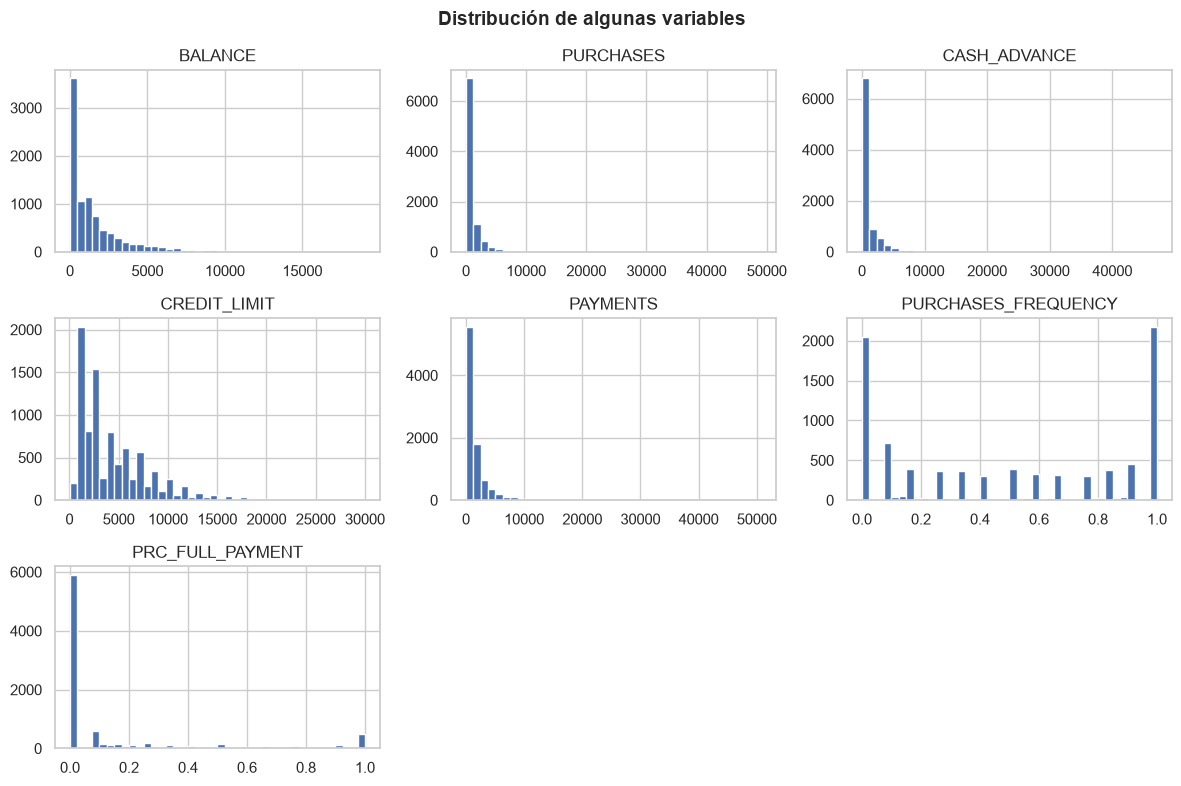

Sesgo (skew). Más de 1 = muy sesgada a la derecha:
BALANCE                2.4
PURCHASES              8.1
CASH_ADVANCE           5.2
CREDIT_LIMIT           1.5
PAYMENTS               5.9
PURCHASES_FREQUENCY    0.1
PRC_FULL_PAYMENT       1.9
dtype: float64


In [21]:
# Pintar histogramas de unas cuantas variables (df[cols].hist...) y observar el sesgo.
cols = ["BALANCE", "PURCHASES", "CASH_ADVANCE", "CREDIT_LIMIT", "PAYMENTS", "PURCHASES_FREQUENCY", "PRC_FULL_PAYMENT"]
df[cols].hist(bins=40, figsize=(12, 8), color="#4c72b0", edgecolor="white",  layout=(3, 3))
plt.suptitle("Distribución de algunas variables", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()
# Medimos el sesgo (skew): ≈ 0 simétrica, > 1 muy sesgada a la derecha
print("Sesgo (skew). Más de 1 = muy sesgada a la derecha:")
print(df[cols].skew().round(1))

> **📝 Observación:**
> - Las variables de **dinero** están muy **sesgadas a la derecha** (skew > 1 en todas; `PURCHASES` llega a **8,1**):
>   casi todos los clientes se concentran a la izquierda y unos pocos tienen valores enormes
>   (`PURCHASES`, `CASH_ADVANCE` y `PAYMENTS` llegan a ~50.000). El **52 %** de los clientes **no usa nunca** el adelanto de efectivo.
> - `CREDIT_LIMIT` está menos sesgado (skew 1,5) y muestra picos en **cifras redondas** (1.000, 3.000…): los bancos asignan límites redondos.
> - `PURCHASES_FREQUENCY` tiene **forma de U** (skew ≈ 0,1: simétrica, no sesgada): el 23 % **nunca** compra con la tarjeta
>   y el 24 % compra **todos los meses**. Ya se intuyen **perfiles de cliente opuestos**.
> - `PRC_FULL_PAYMENT` (skew 1,9): el **66 %** de los clientes **nunca** paga la deuda completa y solo el 5,5 % la paga siempre
>   → la mayoría "arrastra" deuda (y paga intereses).
> - Consecuencia: estas diferencias de escala y los valores extremos refuerzan la necesidad de **escalar** antes del clustering.

### Escalado

K-Means, PCA y casi todos los algoritmos de distancia son **sensibles a la escala**. `CREDIT_LIMIT` llega a miles y `PURCHASES_FREQUENCY` está entre 0 y 1: sin escalar, las variables grandes dominarían. Estandarizamos (media 0, desviación 1).

**¿Qué hace `StandardScaler`?** Transforma cada columna así: **z = (x − media) / desviación típica**.
Después, todas las variables tienen **media 0 y desviación 1**: ninguna domina por tener números más grandes.

**Analogía:** un alumno saca un **8/10** en matemáticas y un **72/100** en historia. ¿En cuál le ha ido mejor?
Comparar 8 con 72 no tiene sentido; lo que sí tiene sentido es preguntar **cuánto está por encima de la media de la clase**.
Eso es justo lo que hace el escalado: expresa cada valor como "cuántas desviaciones está de la media".

- z = 0 → justo en la media · z = +2 → muy por encima · z = −1 → por debajo.
- Escalamos **todo `df`** (no hay train/test: es clustering, igual que con las setas).

In [11]:
# Aplicar StandardScaler a df -> X (array escalado)
scaler = StandardScaler()
X = scaler.fit_transform(df)          # cada columna → media 0, desviación 1

# Comprobación: medias ≈ 0 y desviaciones ≈ 1
pd.DataFrame(X, columns=df.columns).describe().T[["mean", "std", "min", "max"]].round(2)

,mean,std,min,max
BALANCE,0.0,1.0,-0.75,8.40
BALANCE_FREQUENCY,0.0,1.0,-3.70,0.52
PURCHASES,0.0,1.0,-0.47,22.48
ONEOFF_PURCHASES,0.0,1.0,-0.36,24.20
INSTALLMENTS_PURCHASES,0.0,1.0,-0.45,24.43
CASH_ADVANCE,0.0,1.0,-0.47,22.01
PURCHASES_FREQUENCY,-0.0,1.0,-1.22,1.27
ONEOFF_PURCHASES_FREQUENCY,-0.0,1.0,-0.68,2.67
PURCHASES_INSTALLMENTS_FREQUENCY,0.0,1.0,-0.92,1.60
CASH_ADVANCE_FREQUENCY,0.0,1.0,-0.68,6.82


> **📝 Observación:** Tras escalar, todas las variables tienen **media 0 y desviación 1** (el `-0.0` es solo redondeo de decimales).
> Pero el escalado **no elimina los valores extremos**: el máximo de `MINIMUM_PAYMENTS` está a **32 desviaciones** de la media,
> y varias variables de compras superan las 20. K-Means es sensible a estos valores, así que pueden aparecer **clusters pequeños de clientes extremos**.

## PCA

Con 17 variables no podemos pintar un scatter directo. Usamos PCA para (1) ver cuánta información retiene cada componente y (2) proyectar a 2D.

Ajustamos PCA **sin fijar `n_components`** (se calculan las 17 componentes) y miramos la **varianza explicada acumulada**
(*scree plot*): cuánta información conservamos al ir añadiendo componentes.
Llega un punto en que añadir más componentes aporta muy poco: ahí podemos cortar.

**Analogía:** al describir a un alumno, las primeras frases dicen lo importante ("es trabajador, va bien en mates");
las siguientes aportan cada vez menos ("los martes usa boli azul").

Marcamos dos umbrales de referencia: **80 %** y **90 %** de la varianza.

Varianza de cada componente: [0.273 0.203 0.088 0.075 0.062 0.057 0.049 0.043 0.038 0.031 0.024 0.018
 0.014 0.012 0.01  0.003 0.   ]


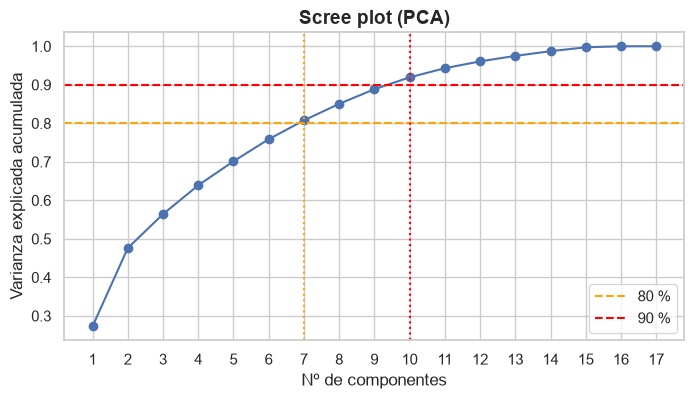

Componentes para el 80 %: 7 · para el 90 %: 10 (de 17 originales)


In [14]:
# 1. Ajustar PCA sin fijar n_components y mirar explained_variance_ratio_
pca_full = PCA(random_state=RANDOM_STATE)
pca_full.fit(X)                                            # calcula las 17 componentes
var_acum = np.cumsum(pca_full.explained_variance_ratio_)   # varianza acumulada
print("Varianza de cada componente:", pca_full.explained_variance_ratio_.round(3))

# 3. Decidir cuantas componentes conservar (primera vez que se supera cada umbral; +1 porque contamos desde 1)
n80 = int(np.argmax(var_acum >= 0.80)) + 1
n90 = int(np.argmax(var_acum >= 0.90)) + 1

# 2. Pintar la varianza explicada acumulada (scree plot)
n_comp = range(1, len(var_acum) + 1)
plt.figure(figsize=(8, 4))
plt.plot(n_comp, var_acum, marker="o")
plt.axhline(0.80, color="orange", linestyle="--", label="80 %")
plt.axhline(0.90, color="red", linestyle="--", label="90 %")
plt.axvline(n80, color="orange", linestyle=":")            # dónde se alcanza el 80 %
plt.axvline(n90, color="red", linestyle=":")               # dónde se alcanza el 90 %
plt.xticks(n_comp)
plt.xlabel("Nº de componentes"); plt.ylabel("Varianza explicada acumulada")
plt.title("Scree plot (PCA)", fontsize=14, fontweight="bold")
plt.legend()
plt.show()

print(f"Componentes para el 80 %: {n80} · para el 90 %: {n90} (de 17 originales)")

> **📝 Observación:**
> - Las 2 primeras componentes explican el **47,6 %** de la varianza (27,3 % + 20,3 %): más que en las setas (30 %),
>   así que la proyección 2D será más representativa.
> - Hacen falta **7 componentes para el 80 %** y **10 para el 90 %**: la información está **repartida** entre las variables
>   (cada una mide un comportamiento distinto: compras, efectivo, pagos, límite…), y no se puede comprimir tanto.
> - Como solo hay 17 variables, haremos el clustering sobre **todas las variables escaladas** (`X`);
>   PCA lo usamos para **entender** los datos y **visualizarlos en 2D**.
> - Los umbrales del 80 % y 90 % no son reglas fijas, sino **referencias habituales**: buscan un equilibrio entre
> conservar la mayor parte de la información y reducir dimensiones. Mirar los dos nos dice cuánto "cuesta" ganar ese 10 % extra.

Proyectamos los clientes a **2 componentes** (47,6 % de la varianza) para verlos en un plano.
Esta vez **no coloreamos**: no hay etiqueta. Solo queremos ver la **forma** de los datos: ¿hay grupos separados como en las setas?

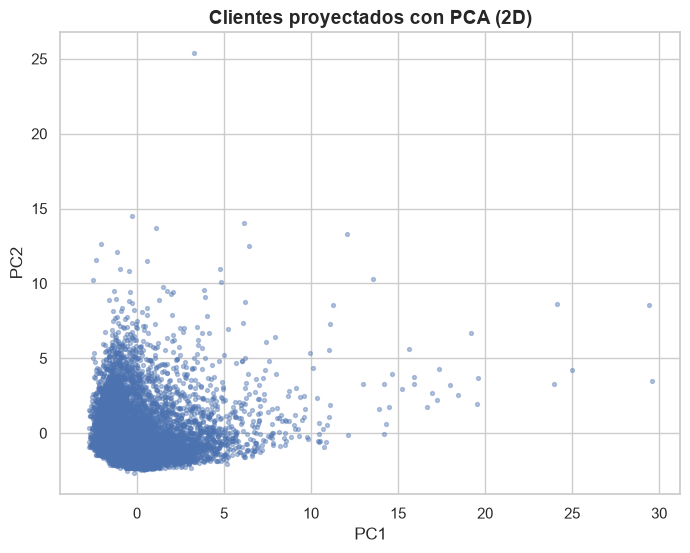

Varianza retenida con 2 componentes: 0.476


In [20]:
# Proyectar X a 2 componentes y pintar el scatter (aun sin colores: no hay etiqueta)
pca2 = PCA(n_components=2, random_state=RANDOM_STATE)
X_2d = pca2.fit_transform(X)          # cada cliente → 2 coordenadas (PC1, PC2)

plt.figure(figsize=(8, 6))
plt.scatter(X_2d[:, 0], X_2d[:, 1], s=8, alpha=0.4, color="#4c72b0")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title("Clientes proyectados con PCA (2D)", fontsize=14, fontweight="bold")
plt.show()

print("Varianza retenida con 2 componentes:", pca2.explained_variance_ratio_.sum().round(3))

In [18]:
# ¿Qué variables pesan más en cada componente? (loadings)
loadings = pd.DataFrame(pca2.components_.T, index=df.columns, columns=["PC1", "PC2"]).round(2)
loadings.sort_values("PC1", ascending=False)


,PC1,PC2
PURCHASES,0.41,0.04
PURCHASES_TRX,0.39,-0.02
ONEOFF_PURCHASES,0.35,0.06
INSTALLMENTS_PURCHASES,0.34,-0.02
PURCHASES_FREQUENCY,0.32,-0.19
ONEOFF_PURCHASES_FREQUENCY,0.29,-0.02
PURCHASES_INSTALLMENTS_FREQUENCY,0.27,-0.18
PAYMENTS,0.27,0.26
CREDIT_LIMIT,0.21,0.24
PRC_FULL_PAYMENT,0.13,-0.19


A diferencia de las setas, aquí no vemos grupos separados a simple vista: es más bien una **nube continua**. El clustering nos ayudará a trazar fronteras útiles dentro de ella.

> **📝 Observación:**
> - **Setas = islas; tarjetas = una sola masa.** Aquí no hay grupos separados: es una **nube continua**, muy densa cerca del origen,
>   que se abre en **dos direcciones** (derecha y arriba). Con 2 componentes vemos el **47,6 %** de la información.
> - Mirando los pesos (*loadings*): **PC1 ≈ eje de compras** (`PURCHASES`, `PURCHASES_TRX`…) y **PC2 ≈ eje de efectivo y deuda**
>   (`CASH_ADVANCE`, `CASH_ADVANCE_FREQUENCY`, `BALANCE`). Las dos "colas" son dos perfiles: clientes que **compran mucho**
>   y clientes que **sacan mucho efectivo**.
> - Hay unos pocos clientes **muy alejados** (valores extremos) que pueden influir en K-Means.
>
> **Idea clave de esta parte:** el clustering **no va a descubrir islas** que ya existían; va a **trazar fronteras útiles**
> dentro de una nube continua. Las fronteras son una **decisión práctica**, no algo natural.
> **Analogía:** el nivel de lectura de una clase va de forma continua del alumno que más lee al que menos,
> pero el profesor forma **3 grupos de lectura** porque así puede **adaptar** su enseñanza. Los grupos no "existían" antes:
> son útiles. Con los clientes pasa lo mismo: los segmentos sirven para **adaptar la estrategia de marketing**.

## Clustering: ¿cuántos segmentos? Codo + Silhouette

**Objetivo:** decidir cuántos segmentos pedirle a K-Means, probando de **k = 2 a k = 8**.
Igual que con las setas, usamos el **codo** (inercia) y el **silhouette**, ahora sobre `X` (las 17 variables escaladas).

**Diferencia clave:** aquí no hay etiqueta con la que comparar. Para elegir k combinamos:
1. **Las métricas:** como criterio principal, elegimos **`best_k` = el k con mayor silhouette**.
2. **La utilidad práctica:** ¿con cuántos segmentos puede trabajar un equipo de marketing?
   Como con los grupos de lectura: 2 grupos son demasiado generales y 10 serían inmanejables.

**Cómo se calcula `best_k`:** `list(k_values)[np.argmax(silhouettes)]`.
`argmax` no devuelve el valor más alto, sino su **posición** en la lista; con esa posición obtenemos el k correspondiente
(es más corto y seguro que buscar el máximo con un `if`).

**Qué esperamos:** un silhouette **bajo para todos los k** (más bajo que en las setas). **No es un error**:
en una nube continua los grupos no están bien separados, y los segmentos serán **fronteras prácticas**, no grupos naturales.

Además mostramos el **tamaño de cada cluster** (`np.bincount`) para detectar clusters diminutos formados por clientes extremos.

k=2: tamaños de los clusters = [3707 5243]
k=3: tamaños de los clusters = [1275 6114 1561]
k=4: tamaños de los clusters = [3977  409 1197 3367]
k=5: tamaños de los clusters = [3910 1385   85 2415 1155]
k=6: tamaños de los clusters = [2231 1316 3037  970   86 1310]
k=7: tamaños de los clusters = [2181  948 1298  446 1153   30 2894]
k=8: tamaños de los clusters = [ 897 2740 2005 1116 1179  364  624   25]


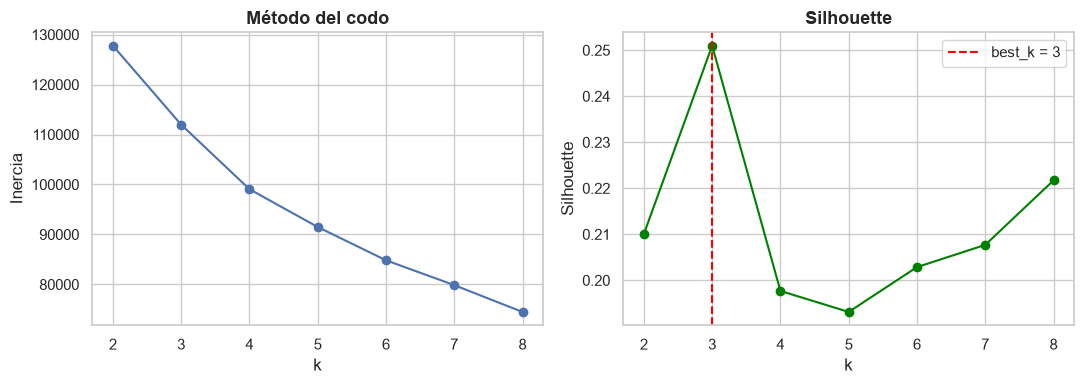

Mejor k según silhouette: 3 · silhouette = 0.251


In [26]:
k_values = range(2, 9)                         # probamos k = 2, 3, ..., 8
inercias, silhouettes = [], []                 # listas vacías donde guardaremos los resultados de cada k

for k in k_values:                             # repetimos el proceso para cada k
    # Ajustar KMeans y guardar inercia + silhouette
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)   # K-Means con k grupos; 10 inicios distintos y se queda con el mejor
    labels = km.fit_predict(X)                 # entrena y devuelve el cluster de cada cliente (0, 1, ..., k-1)
    inercias.append(km.inertia_)               # inercia: suma de distancias de cada cliente a su centroide (para el codo)
    silhouettes.append(silhouette_score(X, labels))   # silhouette: separación de los grupos (-1 a 1, más alto = mejor)
    print(f"k={k}: tamaños de los clusters = {np.bincount(labels)}")   # cuántos clientes hay en cada cluster

# Elegir best_k ANTES de pintar, para poder marcarlo en el gráfico
best_k = list(k_values)[int(np.argmax(silhouettes))]   # argmax = POSICIÓN del silhouette más alto → el k de esa posición

# Pintar las dos curvas y marcar best_k
fig, axes = plt.subplots(1, 2, figsize=(11, 4))      # figura con 2 gráficos lado a lado
axes[0].plot(list(k_values), inercias, marker="o")   # izquierda: curva del codo
axes[0].set_title("Método del codo", fontsize=13, fontweight="bold")
axes[0].set(xlabel="k", ylabel="Inercia")
axes[1].plot(list(k_values), silhouettes, marker="o", color="green")   # derecha: curva de silhouette
axes[1].axvline(best_k, color="red", linestyle="--", label=f"best_k = {best_k}")
axes[1].set_title("Silhouette", fontsize=13, fontweight="bold")
axes[1].set(xlabel="k", ylabel="Silhouette")
axes[1].legend()
plt.tight_layout()                                   # evita que se solapen títulos y ejes
plt.show()

print("Mejor k según silhouette:", best_k, "· silhouette =", round(max(silhouettes), 3))

> **📝 Observación:**
> - **`best_k = 3`** (silhouette **0,251**). Pero el silhouette es **bajo para todos los k** (0,19–0,25), muy lejos del 0,495 de las setas:
>   confirma que es una **nube continua** y que los segmentos serán **fronteras prácticas**.
> - El **codo no es claro**: la inercia baja de forma suave, sin un punto de giro evidente.
> - A partir de k = 5 aparecen **clusters diminutos** (85, 30 o 25 clientes): K-Means dedica un grupo entero a unos pocos
>   **clientes extremos** (los valores de z ≈ 20–30 que vimos al escalar).
> - Con k = 3 los tamaños son razonables (1275 · 6114 · 1561) y es un número **manejable** para marketing.
>   Eso sí, un cluster concentra el 68 % de los clientes: veremos si los segmentos son lo bastante **útiles** al interpretarlos.

### K-Means final

Entrenamos K-Means con el **k elegido (`best_k = 3`)** y guardamos las etiquetas en `km_labels`: es el número de segmento (0, 1 o 2) de cada cliente.

- Miramos **cuántos clientes hay en cada cluster** (y su %) para ver si los grupos están equilibrados.
- Los pintamos sobre la **proyección PCA 2D** (`X_2d`) para ver cómo se reparten en la nube.

Estas etiquetas las reutilizaremos después en el t-SNE y, sobre todo, en la **interpretación de perfiles** (heatmap).

   clientes     %
0      1275  14.2
1      6114  68.3
2      1561  17.4


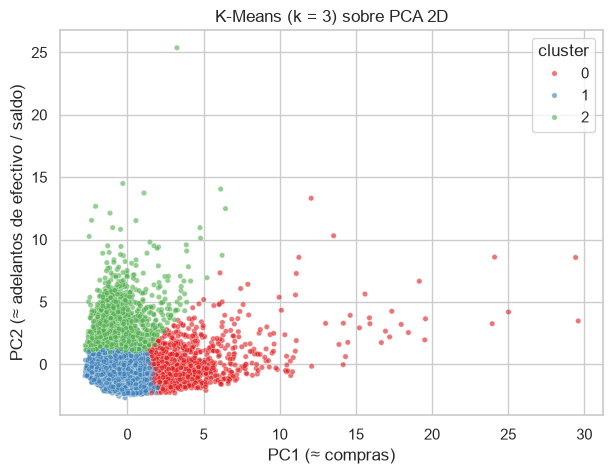

In [27]:
# Entrenar KMeans con best_k, guardar las etiquetas y mirar el tamano de cada cluster
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=RANDOM_STATE)  # modelo final con k = 3
km_labels = kmeans.fit_predict(X)                  # entrena y devuelve el cluster (0, 1, 2) de cada cliente

# Tamaño de cada cluster (número y %)
tamanos = pd.Series(km_labels).value_counts().sort_index()   # cuenta clientes por cluster, ordenado 0,1,2
print(pd.DataFrame({"clientes": tamanos,                     # tabla con el número...
                    "%": (tamanos / len(km_labels) * 100).round(1)}))  # ...y el porcentaje

# Ver los clusters sobre la proyección PCA 2D
plt.figure(figsize=(7, 5))
sns.scatterplot(x=X_2d[:, 0], y=X_2d[:, 1], hue=km_labels,   # PC1 vs PC2, color = cluster
                palette="Set1", s=15, alpha=0.6)            # puntos pequeños y semitransparentes (8950 clientes)
plt.xlabel("PC1 (≈ compras)")
plt.ylabel("PC2 (≈ adelantos de efectivo / saldo)")
plt.title(f"K-Means (k = {best_k}) sobre PCA 2D")
plt.legend(title="cluster")
plt.show()

> **📝 Observación:**
> - Tamaños: **cluster 0 = 1275 (14,2 %)**, **cluster 1 = 6114 (68,3 %)**, **cluster 2 = 1561 (17,4 %)**: los mismos que en la selección de k.
> - Los grupos están **desequilibrados**: el cluster 1 reúne a más de dos tercios de los clientes.
> - En la proyección PCA 2D cada cluster ocupa una **zona de la nube**:
>   - **Cluster 0** se extiende hacia la derecha, en la dirección de **PC1 (compras)** (los que compran mucho… ¡como yo! 🛍️).
>   - **Cluster 2** se extiende hacia arriba, en la dirección de **PC2 (adelantos de efectivo / saldo)**.
>   - **Cluster 1** queda en el **núcleo denso**, abajo a la izquierda (poca actividad).
> - No hay huecos entre los colores: los grupos se tocan. Es otra vez la **nube continua**, cortada en **fronteras prácticas**.
> - De momento son hipótesis visuales; las confirmaremos con las **medias de cada cluster** en la interpretación de perfiles.

### Comparativa de algoritmos

Sin etiqueta, comparamos con **métricas internas**: *silhouette* y *Calinski-Harabasz* (más alto = mejor) y *Davies-Bouldin* (más bajo = mejor).

Comparamos **3 algoritmos con el mismo k = 3** sobre los datos escalados `X`:

| Algoritmo | Cómo agrupa |
|---|---|
| **K-Means** | Asigna cada cliente al **centro más cercano** (grupos "redondos"). |
| **Aglomerativo (ward)** | Une clientes **de abajo arriba**, juntando cada vez los dos grupos más parecidos. |
| **GMM** | Supone que cada grupo es una **campana gaussiana** y da probabilidades de pertenencia. |

Como **no hay etiqueta**, no podemos usar ARI/NMI como en las setas. Usamos solo métricas internas:
- **Silhouette** (de -1 a 1, ↑ mejor): ¿cada cliente está más cerca de su grupo que del vecino?
- **Davies-Bouldin** (↓ mejor): ¿los grupos son compactos y están separados?
- **Calinski-Harabasz** (↑ mejor): dispersión entre grupos / dispersión dentro de los grupos.

Añadimos también el **tamaño de los clusters** para ver si algún algoritmo crea grupos muy desequilibrados.

In [28]:
# Definir evaluar(nombre, labels, X) con silhouette, davies_bouldin y calinski_harabasz
# (sin ARI: no hay etiqueta). Comparar KMeans, Aglomerativo y GMM.
def evaluar(nombre, labels, X):                        # devuelve un diccionario con las métricas de un algoritmo
    return {
        "algoritmo": nombre,
        "silhouette ↑": round(silhouette_score(X, labels), 3),          # cohesión vs separación
        "davies_bouldin ↓": round(davies_bouldin_score(X, labels), 3),  # compacidad / separación
        "calinski_harabasz ↑": round(calinski_harabasz_score(X, labels), 1),  # dispersión entre / dentro
        "tamaños": np.bincount(labels),                                 # clientes por cluster
    }

agg_labels = AgglomerativeClustering(n_clusters=best_k, linkage="ward").fit_predict(X)  # jerárquico (ward)
gmm_labels = GaussianMixture(n_components=best_k, random_state=RANDOM_STATE).fit_predict(X)  # mezcla gaussiana

resultados = pd.DataFrame([
    evaluar("K-Means", km_labels, X),                  # reutilizamos las etiquetas del K-Means final
    evaluar("Aglomerativo", agg_labels, X),
    evaluar("GMM", gmm_labels, X),
])
resultados

,algoritmo,silhouette ↑,davies_bouldin ↓,calinski_harabasz ↑,tamaños
0,K-Means,0.251,1.592,1605.0,"[1275, 6114, 1561]"
1,Aglomerativo,0.167,1.850,1239.3,"[2881, 4875, 1194]"
2,GMM,0.098,2.997,815.8,"[2606, 2934, 3410]"


> **📝 Observación:**
> - **K-Means gana en las tres métricas**: mayor silhouette (**0,251**), menor Davies-Bouldin (**1,59**) y mayor Calinski-Harabasz (**1605**).
>   Aquí las métricas **no se contradicen**, así que la elección es clara.
> - **Aglomerativo** queda en segundo lugar y reparte los clientes de otra forma (2881 / 4875 / 1194): el grupo grande es menos dominante.
> - **GMM es el peor** (silhouette 0,098, DB ≈ 3) y crea tres grupos casi del mismo tamaño.
>   Sus campanas gaussianas se **solapan mucho** en una nube continua, así que los grupos quedan mal separados.
> - Aun así, **todos los silhouettes son bajos** (< 0,3): ningún algoritmo encuentra grupos realmente separados. Lo confirma otra vez: son **fronteras prácticas**.
> - **Elegimos K-Means (k = 3)** para la interpretación de perfiles: mejores métricas y además es el más fácil de explicar a negocio (cada segmento tiene un "cliente medio", su centro).

### Dendrograma

In [ ]:
# linkage + dendrogram sobre una muestra de X

### DBSCAN: ¿hay clusters de densidad aquí?

Probamos DBSCAN. Veréis que en alta dimensión tiende a juntar casi todo en **un solo cluster** y marcar el resto como **ruido**. Eso nos dice algo importante: estos datos son una nube continua, no grupos separados por densidad. Aquí DBSCAN funciona mejor como **detector de atípicos** que como segmentador.

In [ ]:
# Ejecutar DBSCAN sobre la proyeccion PCA(2). Observar cuantos clusters y cuanto ruido.

### Visualización de los segmentos (t-SNE)

Proyectamos con t-SNE (sobre una muestra) y coloreamos por el segmento de K-Means.

In [ ]:
# t-SNE sobre una muestra de X, coloreado por el cluster de KMeans

## Interpretación de los segmentos

Lo más importante en segmentación: **¿qué caracteriza a cada grupo?** Calculamos la media de cada variable por cluster y la estandarizamos entre clusters (rojo = por encima de la media, azul = por debajo). Así leemos el «perfil» de cada segmento.

In [ ]:
# 1. Anadir la columna 'cluster' al df original (sin escalar)
# 2. Calcular la media de cada variable por cluster
# 3. Estandarizar entre clusters y pintar un heatmap (perfil de cada segmento)

Leyendo el heatmap se pueden nombrar los segmentos en términos de **negocio**, por ejemplo: clientes de alto saldo y muchas compras (VIP), clientes que tiran de adelantos de efectivo (riesgo), clientes poco activos, etc. Ese nombre y la estrategia asociada es justo el entregable que pide el caso.

## Detección de anomalías (Isolation Forest)

Identificamos los clientes con comportamiento más atípico (posible fraude, errores de datos o clientes premium fuera de norma).

In [ ]:
# IsolationForest sobre X, marcar los atipicos (-1) y pintarlos sobre PCA(2)

---
## Para ir más allá (opcional)

- **Ingeniería de KPIs**: derivar variables como *ratio de uso del límite* (`BALANCE / CREDIT_LIMIT`) o *compra media por transacción* suele mejorar mucho los segmentos.
- **UMAP / HDBSCAN** para visualización y clustering por densidad más robusto.
- **Transformación logarítmica** de las variables sesgadas antes de escalar.

## Conclusiones

- Sin etiqueta, la segmentación se valida con métricas internas (*silhouette*, etc.) y, sobre todo, con la **interpretabilidad** de los perfiles.
- Imputar y **escalar** fue imprescindible aquí (a diferencia de las setas).
- K-Means, GMM y Aglomerativo dan segmentos coherentes; DBSCAN reveló que los datos son una nube continua (mejor como detector de atípicos).
- El heatmap de perfiles convierte los clusters en **segmentos de negocio accionables**.